# Análisis exploratorio de los datos — Duke-Breast-Cancer-MRI

Análisis descriptivo de los dos archivos de entrada (`datos/Clinical_and_Other_Features.xlsx` y `datos/Imaging_Features.xlsx`, colección *Duke-Breast-Cancer-MRI* de TCIA; citas y condiciones de uso en `datos/LEEME.md`).

La lectura de los datos, la selección de pacientes, la variable objetivo y la construcción de los bloques se toman de las funciones del pipeline (`pipeline_v2/run_stage2.py`), de modo que las cifras coinciden con las del análisis principal. No se entrenan modelos ni se evalúan asociaciones con el desenlace.

Las correlaciones de la sección 7 se calculan sobre la cohorte completa con fines descriptivos. En los modelos, el filtro de correlación, la imputación, la estandarización y el PCA se ajustan solo con los datos de entrenamiento de cada partición. El PCA descriptivo global y la frecuencia de selección de componentes se presentan en `analisis_complementarios/pca_descriptivo.py` (Figura 3.2) y en la Figura A.3.1.

## 0 · Configuración

In [1]:
import re
import runpy
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd()                                   # el notebook se ejecuta desde la raíz del repositorio
assert (ROOT / "datos" / "Clinical_and_Other_Features.xlsx").exists(), "ejecutar desde la raíz del repositorio"
sys.path.insert(0, str(ROOT / "pipeline_v2"))
sys.path.insert(0, str(ROOT / "elementos_visuales_finales" / "fuentes" / "codigo"))

import run_stage2 as s                              # lectura, cohorte y bloques del pipeline
import comun as k                                   # identidad visual de las figuras de la tesis

mpl = k.preparar_matplotlib()
import matplotlib.pyplot as plt
mpl.rcParams.update({"figure.dpi": 110})
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 90)

T, SEQ = k.TINTA, k.COMP["secuencial_petroleo"]
NEG, POS = k.COMP["clases"]["negativa"], k.COMP["clases"]["positiva"]
CM = k.CM

## 1 · Estructura y contenido de los datos

El Excel clínico (hoja `Data`) tiene una fila superior de grupos, una fila con los nombres de columna y una fila de leyenda con la codificación de cada variable; los pacientes empiezan a continuación. `run_stage2.leer_clinico` descarta la fila de grupos y asigna nombres únicos a 16 columnas cuyo nombre figura en la fila de grupos o en la leyenda; `load_raw` descarta la fila de leyenda. El Excel de características de imagen no tiene fila de leyenda.

In [2]:
raw = s.leer_clinico("Data")
leyenda = raw.iloc[1]
clin, rad = s.load_raw()
estructura = pd.Series({
    "Pacientes (Excel clínico)": len(clin),
    "Columnas (Excel clínico)": clin.shape[1],
    "Pacientes (Excel de imagen)": len(rad),
    "Características de imagen": rad.shape[1] - 1,
}, name="valor").to_frame()
display(estructura)

armonizadas = pd.DataFrame([(j, orig if orig else "(vacío)", nuevo)
                            for j, (orig, nuevo) in s.ENCABEZADOS_ARMONIZADOS.items()],
                           columns=["Índice", "Encabezado en el archivo oficial", "Nombre en el análisis"])
display(armonizadas)

print("Ejemplos de la fila de leyenda (codificación):")
for c in ["ER status", "Menopause (at diagnosis)", s.TARGET_COL]:
    print(f"  {c!r}: {str(leyenda[list(raw.iloc[0]).index(c)])[:110]!r}")

,valor
Pacientes (Excel clínico),922
Columnas (Excel clínico),98
Pacientes (Excel de imagen),922
Características de imagen,529


,Índice,Encabezado en el archivo oficial,Nombre en el análisis
0,23,ER,ER status
1,24,PR,PR status
2,25,HER2,HER2 status
3,31,Tumor Grade,Tumor Grade (Tubule)
4,32,(vacío),Tumor Grade (Nuclear)
5,33,(vacío),Tumor Grade (Mitotic)
6,38,Bilateral Information,Bilateral breast cancer
7,39,(vacío),Bilateral different. Rec status
8,40,(vacío),Bilateral. Side Annotated
9,41,For Other Side If Bilateral,For Other Side If Bilateral. Side of cancer


Ejemplos de la fila de leyenda (codificación):
  'ER status': '{0 = neg,\n1 = pos}'
  'Menopause (at diagnosis)': '{0 = pre,\n1 = post,\n2 = N/A}'
  'Overall Near-complete Response:  Stricter Definition': '{0 = not complete or near-complete, 1 = complete, 2 = near-complete, 3 = pathologic assessment not available, '


## 2 · Integración de los archivos y controles de calidad

`Patient ID` es la clave de unión 1:1 entre ambos archivos; se usa solo para unirlos y no es predictor.

In [3]:
nombres = pd.Series(clin.columns.astype(str))
controles = pd.Series({
    "IDs duplicados (clínico)": int(clin[s.ID_COL].duplicated().sum()),
    "IDs duplicados (imagen)": int(rad[s.ID_COL].duplicated().sum()),
    "IDs en ambos archivos": len(set(clin[s.ID_COL]) & set(rad[s.ID_COL])),
    "Nombres de columna repetidos (clínico)": int(nombres[nombres != "nan"].duplicated().sum()),
    "Columnas de imagen no numéricas": int((rad.drop(columns=s.ID_COL).dtypes == "object").sum()),
}, name="valor").to_frame()
display(controles)
assert controles.loc["IDs en ambos archivos", "valor"] == 922
assert controles.loc[["IDs duplicados (clínico)", "IDs duplicados (imagen)"], "valor"].eq(0).all()

,valor
IDs duplicados (clínico),0
IDs duplicados (imagen),0
IDs en ambos archivos,922
Nombres de columna repetidos (clínico),3
Columnas de imagen no numéricas,0


## 3 · Selección de la cohorte y variable objetivo

Inclusión: tratamiento neoadyuvante con quimioterapia y evaluación anatomopatológica de la respuesta. Desenlace: respuesta completa o casi completa según *Overall Near-complete Response: Stricter Definition*. Variable objetivo: códigos 1 y 2 → clase 1; código 0 → clase 0; código 3 (sin evaluación anatomopatológica) → excluido. La clase 1 no equivale a respuesta patológica completa.

,Paso,Pacientes,Exclusiones
0,Colección Duke-Breast-Cancer-MRI,922,
1,Con tratamiento neoadyuvante,312,excluidas 581 sin tratamiento neoadyuvante y 29 sin dato
2,Con quimioterapia neoadyuvante,292,excluidas 19 solo endocrina y 1 solo anti-HER2
3,Cohorte analítica,281,excluidas 11 sin evaluación anatomopatológica (código 3)


,Significado,Variable objetivo,Pacientes con quimioterapia neoadyuvante
Código,,,
0,Sin respuesta completa ni casi completa,Clase 0,188
1,Respuesta completa,Clase 1,64
2,Respuesta casi completa,Clase 1,29
3,Sin evaluación anatomopatológica,Excluido,11


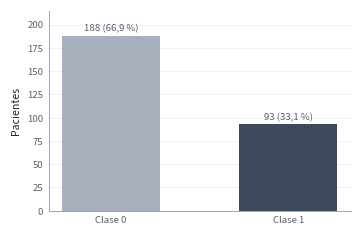

In [4]:
from figuras_diagramas import datos_flujo_cohorte   # misma función que la Figura 3.1
d = datos_flujo_cohorte()
flujo = pd.DataFrame([
    ("Colección Duke-Breast-Cancer-MRI", d["total"], ""),
    ("Con tratamiento neoadyuvante", d["neo"], f"excluidas {d['no_neo']} sin tratamiento neoadyuvante y {d['neo_sin_dato']} sin dato"),
    ("Con quimioterapia neoadyuvante", d["qt"], f"excluidas {d['solo_endocrina']} solo endocrina y {d['solo_antiher2']} solo anti-HER2"),
    ("Cohorte analítica", d["final"], f"excluidas {d['codigo3']} sin evaluación anatomopatológica (código 3)"),
], columns=["Paso", "Pacientes", "Exclusiones"])
display(flujo)

merged, y, rad_cols, meta = s.build_cohort()
assert (meta["n"], meta["n_pos"], meta["n_neg"]) == (d["final"], d["clase1"], d["clase0"]) == (281, 93, 188)

tgt = s._to_num(clin[s.TARGET_COL])
con_qt = (s._to_num(clin["Received Neoadjuvant Therapy or Not"]) == 1) & (s._to_num(clin["Neoadjuvant Chemotherapy"]) == 1)
codigos = pd.DataFrame({
    "Significado": ["Sin respuesta completa ni casi completa", "Respuesta completa", "Respuesta casi completa",
                    "Sin evaluación anatomopatológica"],
    "Variable objetivo": ["Clase 0", "Clase 1", "Clase 1", "Excluido"],
    "Pacientes con quimioterapia neoadyuvante": [int((con_qt & (tgt == c)).sum()) for c in (0, 1, 2, 3)],
}, index=pd.Index([0, 1, 2, 3], name="Código"))
display(codigos)

fig, ax = plt.subplots(figsize=(9 * CM, 6 * CM))
n0, n1 = int((y == 0).sum()), int(y.sum())
ax.bar(["Clase 0", "Clase 1"], [n0, n1], color=[NEG, POS], width=0.55, zorder=3)
for i, n in enumerate((n0, n1)):
    ax.text(i, n + 3, f"{n} ({k.pct(n / len(y))})", ha="center", va="bottom", fontsize=7, color=T["secundaria"])
ax.set_ylabel("Pacientes"); ax.set_ylim(0, 215); ax.grid(axis="x", visible=False)
plt.show()

## 4 · Caracterización clínica

Variables del bloque C en la cohorte analítica (N = 281), con el tratamiento definitivo de los datos faltantes. La tabla se genera con `analisis_complementarios/caracterizacion_cohorte.py` (Tablas 3.1 y A.2), sin pruebas de hipótesis.

In [5]:
runpy.run_path(str(ROOT / "analisis_complementarios" / "caracterizacion_cohorte.py"), run_name="__main__")
tabla_cohorte = pd.read_csv(ROOT / "analisis_complementarios" / "resultados" / "07_caracterizacion_cohorte.csv")
display(tabla_cohorte)

Tabla descriptiva: 57 filas


,Variable,Categoría,Total (n=281),No respondedoras (n=188),Respondedoras (n=93)
0,N,NaN,281,188,93
1,Edad (años),media ± DE,48.8 ± 10.9,49.7 ± 10.7,46.9 ± 11.1
2,Edad (años),mediana [RIC],47.3 [42.0–55.0],48.1 [42.3–55.3],46.8 [38.5–54.8]
3,Menopausia,Premenopausia,161 (57.3%),103 (54.8%),58 (62.4%)
4,Menopausia,Posmenopausia,119 (42.3%),84 (44.7%),35 (37.6%)
5,Menopausia,Sin dato,1 (0.4%),1 (0.5%),0 (0.0%)
6,Raza/etnia,Blanca,174 (61.9%),116 (61.7%),58 (62.4%)
7,Raza/etnia,Negra,85 (30.2%),59 (31.4%),26 (28.0%)
8,Raza/etnia,Asiática,7 (2.5%),6 (3.2%),1 (1.1%)
9,Raza/etnia,Nativa,2 (0.7%),2 (1.1%),0 (0.0%)


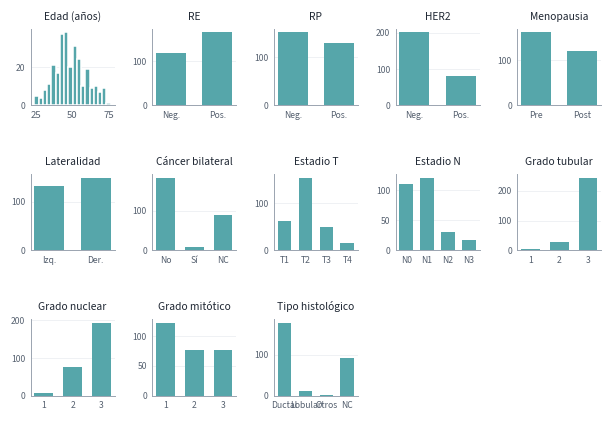

In [6]:
HIST = {1: "Ductal", 2: "Lobular", s.NC_CODE: "NC"}
fmt = lambda pre: (lambda v: f"{pre}{int(v)}" if v == v else None)
cat = {   # (serie, orden de las categorías)
    "RE": (merged.ER_bin.map({0: "Neg.", 1: "Pos."}), ["Neg.", "Pos."]),
    "RP": (merged.PR_bin.map({0: "Neg.", 1: "Pos."}), ["Neg.", "Pos."]),
    "HER2": (merged.HER2_bin.map({0: "Neg.", 1: "Pos."}), ["Neg.", "Pos."]),
    "Menopausia": (merged.menopause_post.map({0: "Pre", 1: "Post"}), ["Pre", "Post"]),
    "Lateralidad": (merged.tumor_side_R.map({0: "Izq.", 1: "Der."}), ["Izq.", "Der."]),
    "Cáncer bilateral": (merged.bilateral_bc.map({0: "No", 1: "Sí", s.NC_CODE: "NC"}), ["No", "Sí", "NC"]),
    "Estadio T": (merged.stage_T.map(fmt("T")), ["T1", "T2", "T3", "T4"]),
    "Estadio N": (merged.stage_N.map(fmt("N")), ["N0", "N1", "N2", "N3"]),
    "Grado tubular": (merged.grade_tubule.map(fmt("")), ["1", "2", "3"]),
    "Grado nuclear": (merged.grade_nuclear.map(fmt("")), ["1", "2", "3"]),
    "Grado mitótico": (merged.grade_mitotic.map(fmt("")), ["1", "2", "3"]),
    "Tipo histológico": (merged.histologic_type.map(lambda v: HIST.get(v, "Otros")), ["Ductal", "Lobular", "Otros", "NC"]),
}
fig, axes = plt.subplots(3, 5, figsize=(17 * CM, 11 * CM), gridspec_kw={"hspace": 0.9, "wspace": 0.45})
axes = axes.ravel()
axes[0].hist(merged.age, bins=18, color=SEQ[3], edgecolor="white", zorder=3)
axes[0].set_title("Edad (años)", fontsize=7.5)
for ax, (nombre, (serie, orden)) in zip(axes[1:], cat.items()):
    vc = serie.value_counts().reindex(orden, fill_value=0)
    assert vc.sum() == serie.notna().sum()
    ax.bar(vc.index, vc.values, color=SEQ[3], width=0.65, zorder=3)
    ax.set_title(nombre, fontsize=7.5)
    ax.tick_params(axis="x", labelsize=5.6 if len(orden) > 4 else 6.3, rotation=35 if len(orden) > 4 else 0)
for ax in axes:
    ax.tick_params(axis="y", labelsize=6.3); ax.grid(axis="x", visible=False)
for ax in axes[len(cat) + 1:]:
    ax.set_visible(False)
plt.show()

## 5 · Datos faltantes, códigos especiales y tratamiento definitivo

La hoja `Legend` define tres códigos especiales además de las celdas vacías. En las variables del modelo, el tratamiento de cada código está implementado en `run_stage2.build_cohort`; los faltantes restantes se imputan dentro de cada partición de entrenamiento según el tipo de variable (`run_stage2.make_preprocessor`).

In [7]:
leg = pd.read_excel(s.CLIN_XLSX, sheet_name="Legend", header=None)
for _, fila in leg.iterrows():
    v = [str(x).strip() for x in fila if pd.notna(x) and str(x).strip()]
    if v and v[0] in ("NC", "NP", "x"):
        print(" = ".join(v[:2]))

coh = clin[clin[s.ID_COL].isin(merged[s.ID_COL])].set_index(s.ID_COL).loc[merged[s.ID_COL]]
crudo = lambda c: coh[c].astype(str).str.strip()
especiales = pd.DataFrame([
    ("histologic_type", "Histologic type", "Celda vacía (no recolectado)", int(coh["Histologic type"].isna().sum()),
     "Categoría explícita NC (no se imputa)"),
    ("bilateral_bc", "Bilateral breast cancer", "NC", int((crudo("Bilateral breast cancer") == "NC").sum()),
     "Categoría explícita NC (no se imputa)"),
    ("stage_N", "Staging(Nodes)#(Nx replaced by -1)[N]", "−1 (Nx) o celda vacía",
     int(merged.stage_N.isna().sum()), "Faltante; imputación en cada partición"),
    ("stage_M", "Staging(Metastasis)#(Mx -replaced by -1)[M]", "−1 (Mx)",
     int((s._to_num(coh["Staging(Metastasis)#(Mx -replaced by -1)[M]"]) == -1).sum()),
     "Reconstruido con Metastatic at Presentation; solo descriptivo (no predictor)"),
    ("menopause_post", "Menopause (at diagnosis)", "2 (no disponible)",
     int((s._to_num(coh["Menopause (at diagnosis)"]) == 2).sum()), "Faltante; imputación en cada partición"),
    ("race", "Race and Ethnicity", "0 (no disponible)",
     int((s._to_num(coh["Race and Ethnicity"]) == 0).sum()), "Faltante; imputación en cada partición"),
], columns=["Variable", "Columna de Duke", "Código", "Pacientes (N = 281)", "Tratamiento"])
display(especiales)

assert int((merged.histologic_type == s.NC_CODE).sum()) == 92 and int((merged.bilateral_bc == s.NC_CODE).sum()) == 90
assert merged.stage_M.value_counts().to_dict() == {0: 280, 1: 1}

x = Info Not Available
NP = Not Pertinent (this data does not apply in this case)
NC = Data Not Collected


,Variable,Columna de Duke,Código,Pacientes (N = 281),Tratamiento
0,histologic_type,Histologic type,Celda vacía (no recolectado),92,Categoría explícita NC (no se imputa)
1,bilateral_bc,Bilateral breast cancer,NC,90,Categoría explícita NC (no se imputa)
2,stage_N,Staging(Nodes)#(Nx replaced by -1)[N],−1 (Nx) o celda vacía,1,Faltante; imputación en cada partición
3,stage_M,Staging(Metastasis)#(Mx -replaced by -1)[M],−1 (Mx),59,Reconstruido con Metastatic at Presentation; solo descriptivo (no predictor)
4,menopause_post,Menopause (at diagnosis),2 (no disponible),1,Faltante; imputación en cada partición
5,race,Race and Ethnicity,0 (no disponible),2,Faltante; imputación en cada partición


In [8]:
IMPUTACION = {"continuous": "mediana", "ordinal": "mediana", "binary": "moda", "nominal": "moda"}
filas = []
for bloque in ("C", "M", "A"):
    for tipo, cols in s.BLOCK_TYPES[bloque].items():
        for c in cols:
            n = int(merged[c].isna().sum())
            if n:
                filas.append((bloque, c, tipo, n, k.pct(n / len(merged)), IMPUTACION[tipo]))
faltantes = pd.DataFrame(filas, columns=["Bloque", "Variable", "Tipo", "Faltantes", "%", "Imputación (dentro de cada partición)"])
display(faltantes.sort_values("Faltantes", ascending=False).reset_index(drop=True))
print(f"Variables de C, M y A sin faltantes tras el tratamiento de códigos: "
      f"{sum(len(c) for b in ('C', 'M', 'A') for c in s.BLOCK_TYPES[b].values()) - len(faltantes)}")

,Bloque,Variable,Tipo,Faltantes,%,Imputación (dentro de cada partición)
0,C,grade_mitotic,ordinal,6,"2,1 %",mediana
1,C,grade_tubule,ordinal,4,"1,4 %",mediana
2,C,grade_nuclear,ordinal,3,"1,1 %",mediana
3,C,stage_T,ordinal,2,"0,7 %",mediana
4,C,race,nominal,2,"0,7 %",moda
5,C,menopause_post,binary,1,"0,4 %",moda
6,C,stage_N,ordinal,1,"0,4 %",mediana
7,A,contrast_agent,nominal,1,"0,4 %",moda


Variables de C, M y A sin faltantes tras el tratamiento de códigos: 25


## 6 · Reconstrucciones y uso de las columnas clínicas

Controles de las dos reconstrucciones del bloque C sobre las 922 pacientes y clasificación de las 98 columnas del Excel clínico según su uso en el código del pipeline.

In [9]:
m_obs = s._to_num(clin["Staging(Metastasis)#(Mx -replaced by -1)[M]"])
m_pres = s._to_num(clin[s.MET_PRES_COL])
ambos = (m_obs >= 0) & m_pres.notna()
print(f"stage_M: concordancia entre M observado y Metastatic at Presentation = "
      f"{int((m_obs[ambos] == m_pres[ambos]).sum())}/{int(ambos.sum())} pacientes con ambos datos")

tl = clin["Tumor Location"].astype(str).str.strip().str.upper().where(lambda v: v.isin(["L", "R"]))
pos = clin["Position"].astype(str).str.strip().str.upper().str.extract(r"^\s*([LR])")[0]
dos = tl.notna() & pos.notna()
print(f"tumor_side_R: Tumor Location y Position concuerdan en {int((tl[dos] == pos[dos]).sum())}/{int(dos.sum())}; "
      f"lado reconstruido desde Position en {int((tl.isna() & pos.notna()).sum())} pacientes (de 922)")

stage_M: concordancia entre M observado y Metastatic at Presentation = 718/719 pacientes con ambos datos
tumor_side_R: Tumor Location y Position concuerdan en 648/651; lado reconstruido desde Position en 271 pacientes (de 922)


In [10]:
fuentes = {}
for bloque, dic in (("C", {**s.C_BINARY, **s.C_ORDINAL, **s.C_NOMINAL, "age": "Date of Birth (Days)"}),
                    ("M", s.M_BINARY), ("A", {**s.A_CONTINUOUS, **s.A_ORDINAL, **s.A_BINARY, **s.A_NOMINAL})):
    for v, col in dic.items():
        fuentes[col] = f"Predictor ({bloque})"
fuentes.update({"Position": "Auxiliar (reconstrucción de tumor_side_R)",
                s.MET_PRES_COL: "Auxiliar (reconstrucción de stage_M)",
                "Staging(Metastasis)#(Mx -replaced by -1)[M]": "Solo descriptiva (stage_M)",
                "Received Neoadjuvant Therapy or Not": "Criterio de inclusión",
                "Neoadjuvant Chemotherapy": "Criterio de inclusión",
                s.TARGET_COL: "Variable objetivo", s.ID_COL: "Identificador (clave de unión)"})
cols = [c for c in clin.columns]
uso = pd.Series([fuentes.get(c, "No utilizada") for c in cols], index=[str(c) for c in cols], name="Uso")
display(uso.value_counts().to_frame("Columnas"))
assert uso.str.startswith("Predictor (C)").sum() == 14 and uso.str.startswith("Predictor (A)").sum() == 14
assert uso.str.startswith("Predictor (M)").sum() == 5 and len(uso) == 98

,Columnas
Uso,
No utilizada,58
Predictor (A),14
Predictor (C),14
Predictor (M),5
Criterio de inclusión,2
Identificador (clave de unión),1
Auxiliar (reconstrucción de stage_M),1
Solo descriptiva (stage_M),1
Auxiliar (reconstrucción de tumor_side_R),1


## 7 · Caracterización descriptiva del bloque radiómico

529 características provistas por los autores de la colección (segmentación y extracción realizadas por Duke). Antes de la validación se eliminan las columnas exactamente duplicadas (`run_stage2.dedup_radiomics`, sin usar la variable objetivo); el resto del preprocesamiento se ajusta dentro de cada partición.

In [11]:
feats = [c for c in rad.columns if c != s.ID_COL]
rad_coh = merged[rad_cols]
resumen_r = pd.Series({
    "Características originales": len(feats),
    "Columnas exactamente duplicadas eliminadas": meta["radiomics_dupes_removed"],
    "Características en el bloque R": len(rad_cols),
    "Con varianza cero (cohorte)": int((rad_coh.std() == 0).sum()),
    "Con algún faltante (922 pacientes)": int(rad[feats].isna().any().sum()),
    "Con algún faltante (cohorte)": int(rad_coh.isna().any().sum()),
    "Celdas faltantes (cohorte)": int(rad_coh.isna().sum().sum()),
    "Pacientes con algún faltante (cohorte)": int(rad_coh.isna().any(axis=1).sum()),
}, name="valor").to_frame()
display(resumen_r)
assert (len(feats), len(rad_cols)) == (529, 509)

region = pd.Series(np.select([pd.Series(rad_cols).str.contains("tissue", case=False),
                              pd.Series(rad_cols).str.contains("tumor", case=False)],
                             ["Parénquima fibroglandular", "Tumor"], "Otras (mama, parénquima global u otras)"),
                   index=rad_cols)
display(region.value_counts().to_frame("Características (según el nombre)"))

falt = rad_coh.isna()
patron = (falt.loc[falt.any(axis=1), falt.any()].astype(int)
          .set_axis(merged.loc[falt.any(axis=1), s.ID_COL], axis=0))
print("Faltantes por paciente (cohorte):", patron.sum(axis=1).to_dict())
print("Clase de esas pacientes:", y[falt.any(axis=1).values].value_counts().sort_index().to_dict())

,valor
Características originales,529
Columnas exactamente duplicadas eliminadas,20
Características en el bloque R,509
Con varianza cero (cohorte),0
Con algún faltante (922 pacientes),40
Con algún faltante (cohorte),21
Celdas faltantes (cohorte),97
Pacientes con algún faltante (cohorte),7


,Características (según el nombre)
Parénquima fibroglandular,282
Tumor,202
"Otras (mama, parénquima global u otras)",25


Faltantes por paciente (cohorte): {'Breast_MRI_103': 16, 'Breast_MRI_253': 16, 'Breast_MRI_258': 16, 'Breast_MRI_282': 16, 'Breast_MRI_385': 16, 'Breast_MRI_651': 13, 'Breast_MRI_816': 4}
Clase de esas pacientes: {0: 5, 1: 2}


Pares con |r| > 0,95: 466 de 129286; características con algún par |r| > 0,95: 333 de 509


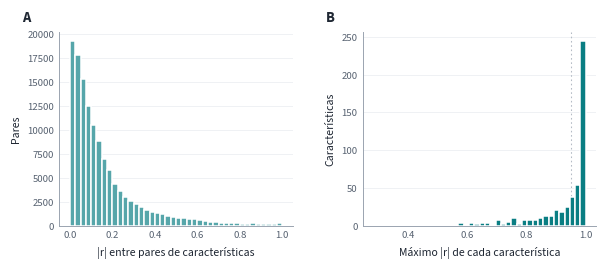

In [12]:
X = rad_coh.fillna(rad_coh.median())
r = np.abs(np.corrcoef(X.values, rowvar=False))
np.fill_diagonal(r, np.nan)
r_max = np.nanmax(r, axis=0)
tri = r[np.triu_indices_from(r, k=1)]
print(f"Pares con |r| > 0,95: {int((tri > 0.95).sum())} de {tri.size}; "
      f"características con algún par |r| > 0,95: {int((r_max > 0.95).sum())} de {len(rad_cols)}")

fig, (a, b) = plt.subplots(1, 2, figsize=(16 * CM, 5.8 * CM), gridspec_kw={"wspace": 0.3})
a.hist(tri, bins=40, color=SEQ[3], edgecolor="white", zorder=3)
a.set_xlabel("|r| entre pares de características"); a.set_ylabel("Pares")
b.hist(r_max, bins=40, color=SEQ[4], edgecolor="white", zorder=3)
b.axvline(0.95, **k.et.linea_referencia())
b.set_xlabel("Máximo |r| de cada característica"); b.set_ylabel("Características")
for ax in (a, b):
    ax.grid(axis="x", visible=False)
k.letra_panel(a, "A"); k.letra_panel(b, "B")
plt.show()

## 8 · Síntesis de las decisiones implementadas

- **Lectura:** fila de grupos y fila de leyenda descartadas; 16 encabezados armonizados (`leer_clinico`, `load_raw`).
- **Cohorte:** 922 → 312 → 292 → 281 pacientes; variable objetivo con 93 pacientes de clase 1 y 188 de clase 0 (`build_cohort`).
- **Códigos especiales:** `histologic_type` y `bilateral_bc` con categoría explícita NC y codificación one-hot dentro del bloque C; Nx, menopausia y raza no disponibles como faltantes imputados dentro de cada partición; `stage_M` reconstruido y solo descriptivo.
- **Bloques:** C (14 variables), M (5) y A (14) predictores, con columnas auxiliares solo para reconstrucciones.
- **Bloque R:** 529 → 509 características por eliminación de columnas duplicadas; imputación, filtro de correlación |r| > 0,95, estandarización y PCA ajustados dentro de cada partición de entrenamiento.